# 01 · Explore the BTS flight data (one month: July 2025)

**Goal (CLAUDE.md, Phase 1, step 1.2):** understand the flight table before building anything on it.
We use **one month only** (July 2025): it is big enough to see real patterns and small enough to run fast.

Rules used in this notebook:
- The raw ZIP is read directly from `data_dir` (outside the repo). **Nothing is written to disk.**
- Time columns are read **as text** (`"0659"` must not become `659`).
- The delay-cause columns are only **looked at** here. They are known after the flight, so they are **never model inputs**.

## 0. Setup

**What:** import the libraries and read `config.yaml` to find the data folder and the 10 hubs.
**Why:** paths are never written by hand in the code, so the same notebook works on another PC by changing only `config.yaml`.

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# The notebook runs from notebooks/, config.yaml sits one folder up (the repo root).
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((REPO / "config.yaml").read_text(encoding="utf-8"))

HUBS = cfg["hubs"]
BTS_ZIP = Path(cfg["data_dir"]) / "raw" / "bts" / "bts_2025_07.zip"
print("hubs:", HUBS)
print("file:", BTS_ZIP, "| exists:", BTS_ZIP.exists())

hubs: ['ATL', 'ORD', 'DFW', 'DEN', 'LAX', 'JFK', 'CLT', 'LAS', 'PHX', 'SEA']
file: C:\data\flight-delay\raw\bts\bts_2025_07.zip | exists: True


**What:** read the month. The ZIP holds a CSV **and** a `readme.html`, so we open the `.csv` member by name.
We read only the columns we need (110 exist), and the 4 clock-time columns as text.

**Why:** fewer columns = less memory and faster. Text times keep the leading zero (`"0659"`), which we need later to build real timestamps.

In [2]:
TIME_COLS = ["CRSDepTime", "DepTime", "CRSArrTime", "ArrTime"]   # HHMM local clock times
COLS = [
    "FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Tail_Number",
    "Origin", "Dest", "OriginAirportID", "DestAirportID",
    *TIME_COLS, "CRSElapsedTime",
    "DepDelay", "DepDel15", "ArrDelay", "ArrDel15", "Cancelled", "Diverted",
    "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay",
]


def read_bts_month(zip_path: Path, columns: list[str]) -> pd.DataFrame:
    """Read the CSV inside one BTS monthly ZIP (not the readme), time columns as strings."""
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            return pd.read_csv(f, usecols=columns, dtype={c: str for c in TIME_COLS},
                               low_memory=False)


df = read_bts_month(BTS_ZIP, COLS)
df["FlightDate"] = pd.to_datetime(df["FlightDate"], format="%Y-%m-%d")   # explicit format
print("shape:", df.shape)
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head()

shape: (631428, 24)
memory: 140 MB


,FlightDate,Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,OriginAirportID,Origin,DestAirportID,Dest,CRSDepTime,DepTime,...,ArrDelay,ArrDel15,Cancelled,Diverted,CRSElapsedTime,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025-07-23,AA,N450AN,969,13303,MIA,11057,CLT,0832,0829,...,-5.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
1,2025-07-24,AA,N431AN,969,13303,MIA,11057,CLT,0832,0957,...,74.0,1.0,0.0,0.0,130.0,0.0,0.0,0.0,0.0,74.0
2,2025-07-25,AA,N444UW,969,13303,MIA,11057,CLT,0832,0828,...,-18.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
3,2025-07-26,AA,N462AA,969,13303,MIA,11057,CLT,0832,0827,...,10.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
4,2025-07-27,AA,N458AL,969,13303,MIA,11057,CLT,0832,0836,...,-13.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN


**What:** compare the number of rows with the count found during the download check (631,428).
**Why:** a different number would mean the file was read wrongly (wrong member, cut file, bad parsing).

In [3]:
EXPECTED_ROWS = 631_428
print(f"rows read: {len(df):,} | expected: {EXPECTED_ROWS:,} | match: {len(df) == EXPECTED_ROWS}")
print("dates:", df["FlightDate"].min().date(), "->", df["FlightDate"].max().date())
print("time column types:", df[TIME_COLS].dtypes.unique())

rows read: 631,428 | expected: 631,428 | match: True
dates: 2025-07-01 -> 2025-07-31
time column types: [<StringDtype(na_value=nan)>]


**Question:** Does the row count match 631,428? If one day it does not, what are 2 possible reasons?

**My answer:**
yes it matchest the count
 if  one day it does not it might be because there are no flights in that day they are all canveled or there is a carrier or weather delay 


## 1. Counts: flights, airlines, airports, hubs

**What:** how many flights, airlines and departure airports, and how many flights leave from our 10 hubs.
**Why:** our scope is "flights departing from the 10 hubs". We need to know how much of the US traffic that keeps.

In [4]:
from_hub = df["Origin"].isin(HUBS)
summary = pd.Series({
    "flights": len(df),
    "airlines (Reporting_Airline)": df["Reporting_Airline"].nunique(),
    "origin airports": df["Origin"].nunique(),
    "flights from the 10 hubs": int(from_hub.sum()),
    "share from the 10 hubs (%)": round(100 * from_hub.mean(), 1),
})
summary.to_frame("value")

,value
flights,631428.0
airlines (Reporting_Airline),14.0
origin airports,345.0
flights from the 10 hubs,208298.0
share from the 10 hubs (%),33.0


**What:** flights per hub, as a bar chart.
**Why:** hubs are not equal: a big hub gives the model many more examples than a small one.

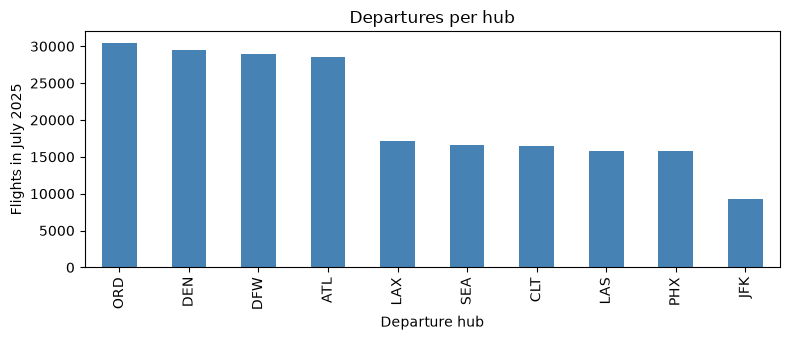

In [5]:
per_hub = df.loc[from_hub, "Origin"].value_counts()
ax = per_hub.plot.bar(figsize=(8, 3.5), color="steelblue")
ax.set_xlabel("Departure hub")
ax.set_ylabel("Flights in July 2025")
ax.set_title("Departures per hub")
plt.tight_layout()
plt.show()

**Question:** What share of all US domestic flights leaves from our 10 hubs? Is one month of it enough data to train on, or why do we need 2024–2025?

**My answer:**
i dont know the share it rperenstnst out of usa but all i know we took airports in  different big states only where ther might be the most flights , and we need two years worth of data since it the trained model will be trained on various season at least each season saw it twice more data can lead to more precise results 

## 2. Is there a unique key for a flight?

**What:** check that (date, airline, flight number, origin, scheduled departure) identifies exactly one row.
**Why:** every later join (weather, radar, previous leg) attaches data **to one flight**. If the key is not unique,
a join can silently duplicate rows. The Gold table test `test_no_duplicate_flights` depends on this.

In [6]:
KEY = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Origin", "CRSDepTime"]

dup = df.duplicated(KEY, keep=False)        # keep=False marks EVERY copy, not only the 2nd
print(f"rows sharing a key: {dup.sum():,} ({100 * dup.mean():.3f} %)")
df.loc[dup, KEY + ["Dest", "Tail_Number", "Cancelled"]].sort_values(KEY).head(10)

rows sharing a key: 0 (0.000 %)


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,CRSDepTime,Dest,Tail_Number,Cancelled


**Question:** Is the key unique? If not, what do the duplicates look like, and what would you add to the key (or remove) to fix it?

**My answer:**
the key is unique it is the Flight_Number_Reporting_Airline , regarding the duplicates you can check it by comapring the columns full if they match hey are duplicate we do a heatmap and we drop one of them 

## 3. Cancelled, diverted and missing tail numbers

**What:** the share of flights that were cancelled, diverted, or have no tail number.
**Why:**
- cancelled flights have **no delay**: they can never be a delay label;
- diverted flights end at another airport: they break the aircraft's chain;
- without a tail number we cannot build the rotation (previous/next leg) at all.

In [ ]:
tail = df["Tail_Number"].astype("string").str.strip()
shares = pd.Series({
    "cancelled": df["Cancelled"].eq(1).mean(),
    "diverted": df["Diverted"].eq(1).mean(),
    "missing tail number": (tail.isna() | tail.eq("")).mean(),
}) * 100
shares.round(2).to_frame("% of flights")

**What:** are missing tail numbers mostly on cancelled flights?
**Why:** if the aircraft never flew, a missing tail is expected; on flown flights it is a real gap in the chain.

In [ ]:
pd.crosstab(tail.isna() | tail.eq(""), df["Cancelled"].eq(1),
            rownames=["tail missing"], colnames=["cancelled"])

**Question:** Why must cancelled flights never be used as a delay label? What happens to the rotation of a flight with no tail number?

**My answer:**

## 4. How are departure delays distributed?

**What:** histogram of `DepDelay` (minutes) for flights that were not cancelled. Two versions:
1. clipped to −30…180 min, normal scale: shows the bulk of flights;
2. full range, **log scale** on the counts: shows the rare, very long delays (the "long right tail").

**Why:** the shape tells us how to train. A long tail means a few huge delays can dominate the error → log transform or capping for regression (CLAUDE.md §11).
Negative values = the flight left **early**.

In [ ]:
flown = df[df["Cancelled"].eq(0)]
dep = flown["DepDelay"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(dep.clip(-30, 180), bins=105, color="steelblue")
axes[0].set_title("DepDelay, clipped to [-30, 180] min")
axes[0].set_xlabel("Departure delay (minutes; values outside the range piled at the edges)")
axes[0].set_ylabel("Number of flights")

axes[1].hist(dep, bins=200, color="darkorange", log=True)
axes[1].set_title("DepDelay, full range, log-scale counts")
axes[1].set_xlabel("Departure delay (minutes)")
axes[1].set_ylabel("Number of flights (log scale)")
plt.tight_layout()
plt.show()

**What:** percentiles, mean vs. median, and the share of flights delayed ≥ 15 min.
**Why:** the 15-min threshold is our classification target; its share tells us how **imbalanced** the classes are.

In [ ]:
pct = dep.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999])
pct.index = [f"p{q * 100:g}" for q in pct.index]
print(f"mean = {dep.mean():.1f} min | median = {dep.median():.1f} min | max = {dep.max():.0f} min")
print(f"share delayed >= 15 min: {100 * (dep >= 15).mean():.1f} %")
pct.round(1).to_frame("DepDelay (min)").T

**What:** check that the BTS flag `DepDel15` really equals `DepDelay >= 15` on flown flights.
**Why:** we will use one of them as the label; they must agree. Disagreements would be a data error to report.

In [ ]:
both = flown.dropna(subset=["DepDelay", "DepDel15"])
mismatch = both["DepDel15"].ne((both["DepDelay"] >= 15).astype(float))
print(f"flown flights checked: {len(both):,} | mismatches: {mismatch.sum():,}")
print(f"flown flights with no DepDelay: {flown['DepDelay'].isna().sum():,}")
both.loc[mismatch, ["FlightDate", "Reporting_Airline", "Origin", "DepDelay", "DepDel15"]].head()

**Question:** Why is the median much lower than the mean? What does the long tail mean for the regression target and for MAE? How imbalanced is the ≥ 15 min class?

**My answer:**

## 5. Where and when are delays bigger?

**What:** average departure delay and share ≥ 15 min by **scheduled local hour** of departure.
**Why:** the CLAUDE.md check question "why do delays grow later in the day?". Local hour is right here: it is the airport's own day.
`CRSDepTime = "2400"` means midnight; we count it as hour 0.

In [ ]:
def scheduled_hour(hhmm: pd.Series) -> pd.Series:
    """Local scheduled hour (0-23) from an 'HHMM' text column; '2400' counts as hour 0."""
    return hhmm.str.zfill(4).str[:2].astype(int) % 24


flown = flown.assign(dep_hour=scheduled_hour(flown["CRSDepTime"]),
                     late15=flown["DepDelay"] >= 15)
by_hour = flown.groupby("dep_hour").agg(flights=("DepDelay", "size"),
                                        mean_delay=("DepDelay", "mean"),
                                        share_15=("late15", "mean"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour.index, 100 * by_hour["share_15"], color="steelblue")
ax.set_xlabel("Scheduled departure hour (local time)")
ax.set_ylabel("% of flights delayed >= 15 min")
ax.set_title("Delay risk by hour of the day (July 2025, all airports)")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()
by_hour.round(2).T

**What:** the same two numbers for each of our 10 hubs (departures only).
**Why:** if hubs behave very differently, the airport is a useful input, and the error analysis (Phase 4) must look per hub.

In [ ]:
hub_flown = flown[flown["Origin"].isin(HUBS)]
by_hub = (hub_flown.groupby("Origin")
          .agg(flights=("DepDelay", "size"), mean_delay=("DepDelay", "mean"),
               share_15=("late15", "mean"))
          .sort_values("share_15", ascending=False))

ax = (100 * by_hub["share_15"]).plot.bar(figsize=(8, 3.5), color="darkorange")
ax.set_xlabel("Departure hub")
ax.set_ylabel("% of departures delayed >= 15 min")
ax.set_title("Delay risk by hub (July 2025)")
plt.tight_layout()
plt.show()
by_hub.round(2)

**What:** the same for each airline.
**Why:** airlines have different schedules, buffers and networks: the airline is likely a strong input.

In [ ]:
by_airline = (flown.groupby("Reporting_Airline")
              .agg(flights=("DepDelay", "size"), mean_delay=("DepDelay", "mean"),
                   share_15=("late15", "mean"))
              .sort_values("share_15", ascending=False))

ax = (100 * by_airline["share_15"]).plot.bar(figsize=(8, 3.5), color="seagreen")
ax.set_xlabel("Airline (BTS code)")
ax.set_ylabel("% of flights delayed >= 15 min")
ax.set_title("Delay risk by airline (July 2025, all airports)")
plt.tight_layout()
plt.show()
by_airline.round(2)

**Question:** Why do delays grow later in the day? Which hub and which airline stand out, and is one month enough to trust that ranking?

**My answer:**

## 6. The delay-cause columns (analysis only)

> ⚠️ **These columns are NEVER model inputs.** `CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`
> and `LateAircraftDelay` are filled **after** the flight, by the airline. Using them would be leakage
> (Golden rule 2). We look at them only to understand *why* flights are late.

**What:** when are the cause columns filled? BTS fills them for **arrival** delays ≥ 15 min, so we compare with `ArrDel15`, not `DepDel15`.
**Why:** if we compared with the departure flag we would see "errors" that are not errors.

In [ ]:
CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

cause_filled = df[CAUSES].notna().any(axis=1)
arr15 = df["ArrDel15"].map({0.0: "0 (on time)", 1.0: "1 (late >= 15)"}).fillna("missing")
pd.crosstab(arr15, cause_filled, rownames=["ArrDel15"], colnames=["cause columns filled"])

**What:** out of all delay minutes explained by a cause, what share comes from each cause?
**Why:** this answers the CLAUDE.md question "what share of delay minutes is *late aircraft*?". A big share = propagation matters, which is the whole point of the rotation modality.

In [ ]:
minutes = df[CAUSES].sum()
share = 100 * minutes / minutes.sum()

ax = share.sort_values().plot.barh(figsize=(7, 3), color="slategray")
ax.set_xlabel("% of all cause-attributed delay minutes")
ax.set_ylabel("Cause")
ax.set_title("Where do delay minutes come from? (July 2025)")
plt.tight_layout()
plt.show()
pd.DataFrame({"minutes": minutes.astype(int), "% of total": share.round(1)})

**Question:** What share of delay minutes is 'late aircraft'? What does it say about delay propagation, and why can none of these columns be a model input?

**My answer:**

---
*End of batch 1. Batch 2 (UTC times, one tail through a day, ground-time distribution and chain-break threshold, consistency check, summary) comes next.*